In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import KMeans
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

# Загружаем встроенный датасет
data = load_wine()
df_clean = pd.DataFrame(data.data, columns=data.feature_names)

# Стандартизация признаков (обязательный этап перед кластеризацией)[cite: 4, 5]
sc = StandardScaler()
sc_df = sc.fit_transform(df_clean)

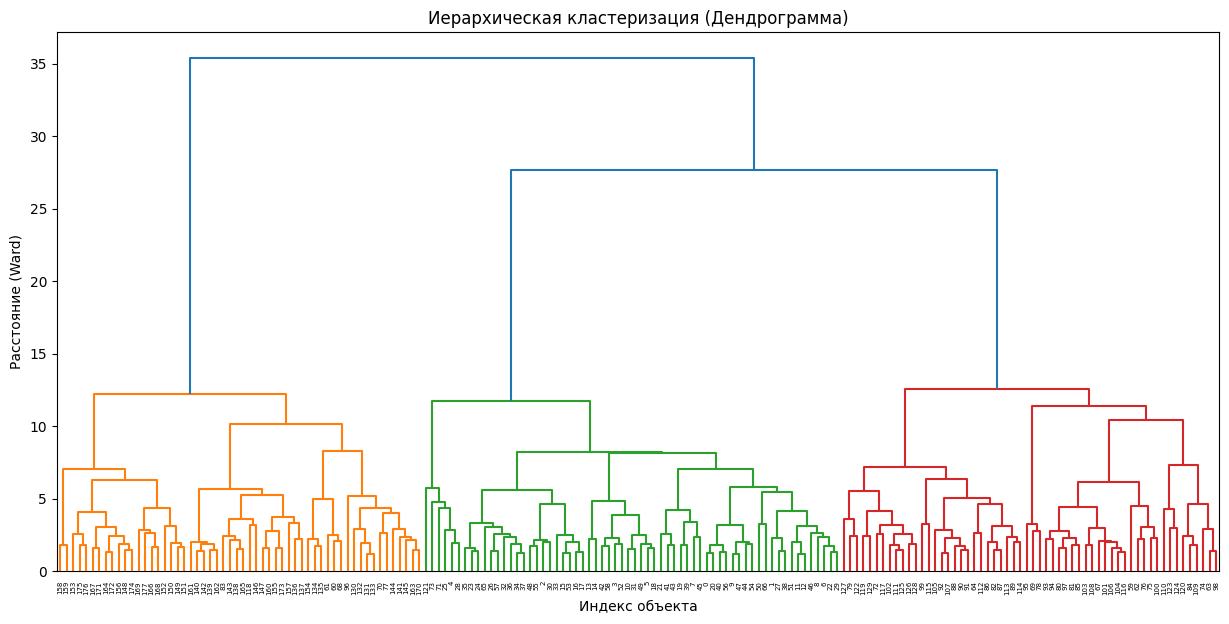

In [2]:
# Построение матрицы связок методом Варда[cite: 4]
linked = linkage(sc_df, method="ward")

# Визуализация дендрограммы[cite: 4]
plt.figure(figsize=(15, 7))
dendrogram(linked, orientation="top")
plt.title("Иерархическая кластеризация (Дендрограмма)")
plt.xlabel("Индекс объекта")
plt.ylabel("Расстояние (Ward)")
plt.show()

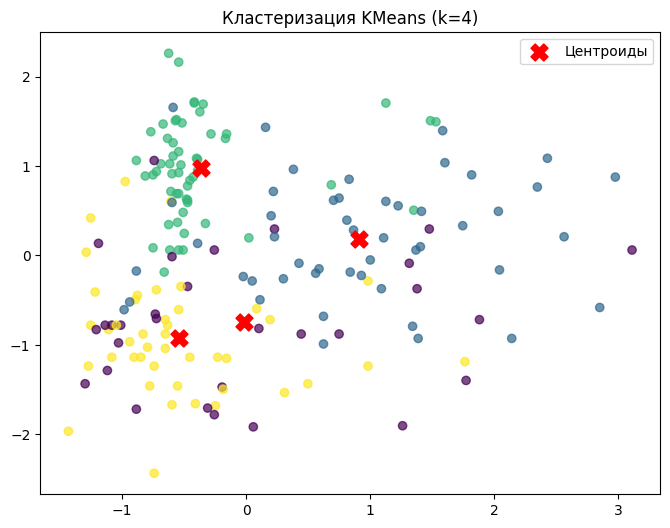

Координаты точек центроидов:
 [[-0.74356936 -0.01617138  0.10046027  0.29279474  0.32708372  0.64395725
   0.5930736  -0.56286944  0.88264355 -0.70080225  0.31830389  0.61909432
  -0.51331892]
 [ 0.18654314  0.90497145  0.24921026  0.58370348 -0.05063539 -0.988557
  -1.23619475  0.71684172 -0.74960756  0.98849829 -1.19129878 -1.30153966
  -0.38004461]
 [ 0.97576974 -0.36378464  0.24534469 -0.81416494  0.43559525  0.89901929
   0.98462062 -0.61854156  0.54730527  0.24550357  0.47704578  0.77086772
   1.25833074]
 [-0.92047428 -0.54205238 -0.65270611  0.16803997 -0.71111627 -0.46194286
  -0.25847272  0.35865056 -0.45114377 -0.92988738  0.51334104  0.06374748
  -0.79969176]]
Евклидово расстояние между кластерами = 4.933595332854518


In [3]:
n = 4
km = KMeans(n_clusters=n, random_state=1)
labels = km.fit_predict(sc_df)
centers = km.cluster_centers_

# Построение точечной диаграммы с центроидами[cite: 5]
plt.figure(figsize=(8, 6))
plt.scatter(sc_df[:, 1], sc_df[:, 0], c=labels, cmap="viridis", alpha=0.7)
plt.scatter(
    centers[:, 1],
    centers[:, 0],
    color="red",
    s=150,
    marker="X",
    label="Центроиды",
)
plt.title(f"Кластеризация KMeans (k={n})")
plt.legend()
plt.show()

# Вывод координат центроидов и евклидова расстояния[cite: 6]
print("Координаты точек центроидов:\n", centers)
print("Евклидово расстояние между кластерами =", np.linalg.norm(centers))

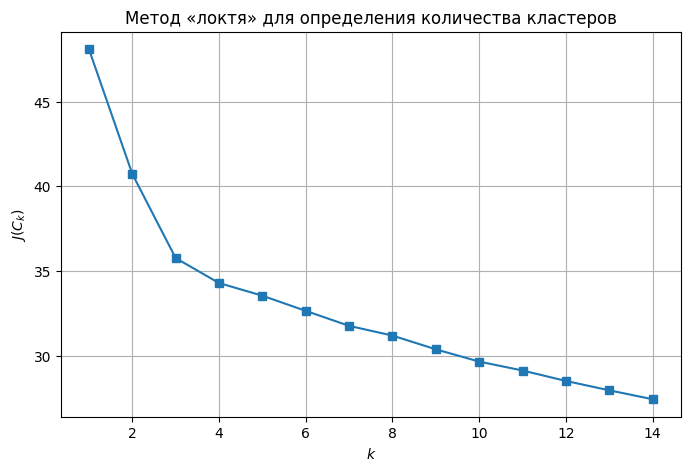

In [4]:
inertia = []
K_range = range(1, 15)

for k in K_range:
  kmeans = KMeans(n_clusters=k, random_state=1).fit(sc_df)
  inertia.append(np.sqrt(kmeans.inertia_))

# График метода «локтя»[cite: 6]
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker="s")
plt.xlabel("$k$")
plt.ylabel("$J(C_k)$")
plt.title("Метод «локтя» для определения количества кластеров")
plt.grid(True)
plt.show()

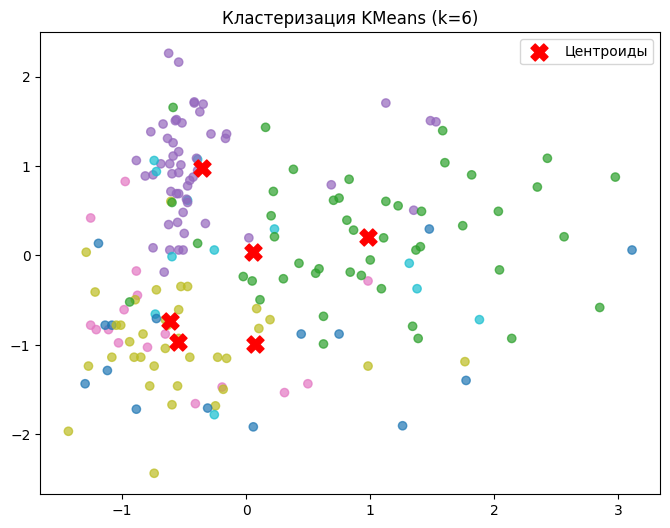


Средние значения признаков для каждого кластера:
           alcohol  malic_acid       ash  alcalinity_of_ash   magnesium  \
Cluster                                                                   
0        12.197333    2.419333  2.239333          19.100000   91.733333   
1        13.171489    3.431702  2.441064          21.595745   98.829787   
2        13.795192    1.941731  2.418077          16.619231  105.615385   
3        12.410000    1.651250  2.171250          17.275000  107.500000   
4        12.217500    1.726944  2.215556          20.902778   87.027778   
5        13.029167    2.394167  2.723333          22.958333  115.666667   

         total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
Cluster                                                                     
0             2.905333    2.775333              0.265333         2.166667   
1             1.674894    0.792979              0.452766         1.165957   
2             2.858846    3.023654       

In [5]:
n_opt = 6
km_opt = KMeans(n_clusters=n_opt, random_state=1)
labels_opt = km_opt.fit_predict(sc_df)
centers_opt = km_opt.cluster_centers_

# Точечная диаграмма для нового числа кластеров[cite: 7]
plt.figure(figsize=(8, 6))
plt.scatter(sc_df[:, 1], sc_df[:, 0], c=labels_opt, cmap="tab10", alpha=0.7)
plt.scatter(
    centers_opt[:, 1],
    centers_opt[:, 0],
    color="red",
    s=150,
    marker="X",
    label="Центроиды",
)
plt.title(f"Кластеризация KMeans (k={n_opt})")
plt.legend()
plt.show()

# Анализ средних значений признаков по полученным кластерам[cite: 7]
df_clean["Cluster"] = labels_opt
cluster_means = df_clean.groupby("Cluster").mean()
print("\nСредние значения признаков для каждого кластера:")
print(cluster_means)